In [1]:
# paramètres

import sys, os, json, warnings
sys.path.append("/home/jovyan/work/pipelines")   # chemin absolu dans le conteneur
from aq import *
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
warnings.filterwarnings("ignore")
os.makedirs(f"{RACINE}/reports", exist_ok=True)
COUCHES = ["BRONZE", "SILVER", "GOLD", "CRM"]
COUCHE_DE_PORTE = {"B": "BRONZE", "S": "SILVER", "G": "GOLD", "C": "CRM"}
print("Lot :", BATCH, "| racine :", RACINE)

Lot : L-2026-10-01 | racine : /home/jovyan/work


In [2]:
# US-29, l’historique des mesures

H = lire("""SELECT m.rule_id, r.dimension, r.severite, r.porte, m.couche, m.table_cible, m.taux_conformite AS taux
            FROM dq.v_derniere_mesure m JOIN dq.regle r USING (rule_id) WHERE m.batch_id = :b""", b=BATCH)
H["taux"] = H.taux.astype(float)
historique = (H.pivot_table(index=["rule_id", "dimension", "severite", "porte"], columns="couche", values="taux", aggfunc="min")
               .reindex(columns=COUCHES).reset_index())
print(historique.to_string(index=False))

regles = lire("SELECT rule_id, porte, severite FROM dq.regle ORDER BY rule_id")
regles["couche_attendue"] = regles.porte.map(COUCHE_DE_PORTE)
mesurees = set(zip(H.rule_id, H.couche))
regles["mesures"] = [int((r, c) in mesurees) for r, c in zip(regles.rule_id, regles.couche_attendue)]
print("\nRègles sans mesure à la couche de leur porte :", regles[(regles.mesures == 0) & (regles.porte != "C")][["rule_id", "porte", "severite"]].values.tolist())

rule_id               dimension      severite porte  BRONZE  SILVER    GOLD   CRM
 RQ-001               Cohérence     BLOQUANTE     S  99.200 100.000 100.000   NaN
 RQ-002         Validité métier     BLOQUANTE     G  99.699  99.702 100.000   NaN
 RQ-003              Complétude AVERTISSEMENT     S  87.998  88.006  89.938   NaN
 RQ-005         Validité format AVERTISSEMENT     S  98.474 100.000 100.000   NaN
 RQ-007 Intégrité référentielle     BLOQUANTE     S  96.950 100.000 100.000   NaN
 RQ-009        Validité domaine     BLOQUANTE     S  99.800 100.000     NaN   NaN
 RQ-010        Validité domaine     BLOQUANTE     S  99.400 100.000 100.000   NaN
 RQ-011 Intégrité référentielle     BLOQUANTE     G  99.800  99.798 100.000   NaN
 RQ-012 Intégrité référentielle     BLOQUANTE     G  99.000  98.382 100.000   NaN
 RQ-013 Intégrité référentielle     BLOQUANTE     G  99.700  99.334 100.000   NaN
 RQ-015     Cohérence de statut     BLOQUANTE     G  99.521  99.524 100.000   NaN
 RQ-016     Cohé

couche                   BRONZE  SILVER    GOLD
dimension                                      
Cohérence                 99.20  100.00  100.00
Cohérence de définition     NaN     NaN  100.00
Cohérence de statut       98.80   98.61  100.00
Cohérence inter-tables    98.80   98.80  100.00
Complétude                88.00   97.60   89.94
Complétude, intégrité    100.00     NaN     NaN
Intégrité                   NaN     NaN     NaN
Intégrité référentielle   98.86   99.38  100.00
Traçabilité              100.00  100.00  100.00
Unicité                  100.00  100.00  100.00
Validité domaine          99.60  100.00  100.00
Validité format           98.47  100.00  100.00
Validité métier           99.70   99.70  100.00
Courbe enregistrée : /home/jovyan/work/reports/courbe_qualite.png


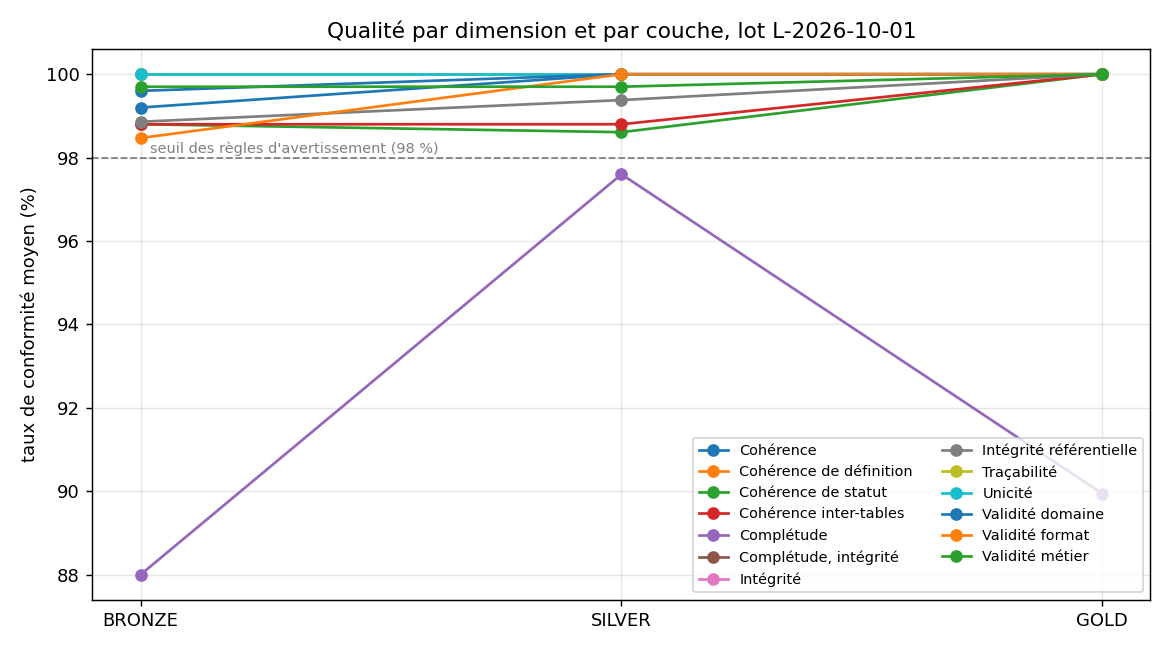

        count     min     max
couche                       
BRONZE      3   98.32  100.00
CRM         1  100.00  100.00
GOLD        1   99.47   99.47
SILVER      2   98.83  100.00


In [3]:
# US-30, la courbe de la qualité

K = lire("SELECT dimension, couche, taux_moyen FROM dq.dq_kpi_dimension WHERE batch_id = :b", b=BATCH)
K["taux_moyen"] = K.taux_moyen.astype(float)
courbe = K.pivot(index="dimension", columns="couche", values="taux_moyen").reindex(columns=["BRONZE", "SILVER", "GOLD"])
print(courbe.round(2).to_string())

fig, ax = plt.subplots(figsize=(9, 5))
for dimension, ligne in courbe.iterrows():
    ax.plot(ligne.index, ligne.values, marker="o", label=dimension)
ax.axhline(98, color="grey", linestyle="--", linewidth=1)
ax.text(0.02, 98.1, "seuil des règles d'avertissement (98 %)", fontsize=8, color="grey")
ax.set_ylabel("taux de conformité moyen (%)"); ax.set_title(f"Qualité par dimension et par couche, lot {BATCH}")
ax.legend(fontsize=8, ncol=2, loc="lower right"); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(f"{RACINE}/reports/courbe_qualite.png", dpi=130); plt.close(fig)
print("Courbe enregistrée :", f"{RACINE}/reports/courbe_qualite.png")
display(Image(f"{RACINE}/reports/courbe_qualite.png"))      # affiche la courbe dans le notebook

dans_le_temps = lire("""SELECT DATE_FORMAT(h.mesure_le, '%Y-%m-%d %H:%i') AS instant, h.couche, ROUND(AVG(h.taux_conformite), 2) AS taux_moyen
                        FROM dq.dq_history h WHERE h.batch_id = :b GROUP BY instant, h.couche ORDER BY h.couche, instant""", b=BATCH)
print(dans_le_temps.groupby("couche").taux_moyen.agg(["count", "min", "max"]))

In [4]:
# US-31, le certificat

DECISION = """
SELECT IF(SUM(m.taux_conformite < r.seuil_min) = 0, 'GO', 'NO_GO') AS decision,
       COUNT(*) AS nb_testees, COALESCE(SUM(m.taux_conformite >= r.seuil_min), 0) AS nb_ok
FROM dq.v_derniere_mesure m JOIN dq.regle r USING (rule_id)
WHERE m.batch_id = :lot AND r.severite = 'BLOQUANTE' AND r.porte IN ('B', 'S', 'G')
  AND m.couche = ELT(FIELD(r.porte, 'B', 'S', 'G'), 'BRONZE', 'SILVER', 'GOLD')"""
EN_ECHEC = """
SELECT m.rule_id, m.table_cible, m.taux_conformite, r.seuil_min
FROM dq.v_derniere_mesure m JOIN dq.regle r USING (rule_id)
WHERE m.batch_id = :lot AND r.severite = 'BLOQUANTE' AND r.porte IN ('B', 'S', 'G')
  AND m.couche = ELT(FIELD(r.porte, 'B', 'S', 'G'), 'BRONZE', 'SILVER', 'GOLD') AND m.taux_conformite < r.seuil_min"""

def emettre(lot, signataire="Data Owner"):
    d = lire(DECISION, lot=lot).iloc[0]
    ko = lire(EN_ECHEC, lot=lot)
    commentaire = "Aucune regle bloquante en echec" if d.decision == "GO" else "Regles en echec : " + ", ".join(f"{r.rule_id} ({r.table_cible})" for r in ko.itertuples())
    empreinte = empreinte_gold()
    executer("""INSERT INTO dq.certificat_qualite (certificat_id, batch_id, nb_bloquantes_testees, nb_bloquantes_ok, empreinte_gold, decision, signataire, commentaire)
                VALUES (:i, :b, :nt, :nok, :e, :d, :s, :c)
                ON DUPLICATE KEY UPDATE emis_le = NOW(), nb_bloquantes_testees = :nt, nb_bloquantes_ok = :nok, empreinte_gold = :e, decision = :d, signataire = :s, commentaire = :c""",
             i=f"CERT-{lot}", b=lot, nt=int(d.nb_testees), nok=int(d.nb_ok), e=empreinte, d=d.decision, s=signataire, c=commentaire[:500])
    return ko

ko = emettre(BATCH)
print(lire("SELECT certificat_id, decision, nb_bloquantes_ok, nb_bloquantes_testees, LEFT(empreinte_gold, 16) AS empreinte_debut, signataire, commentaire FROM dq.certificat_qualite WHERE batch_id = :b", b=BATCH).to_string(index=False))
print("Mesures bloquantes sous leur seuil :", ko.rule_id.tolist() or "aucune")

executer("DELETE FROM dq.dq_history WHERE batch_id = 'L-TEST'")
executer("""INSERT INTO dq.dq_history (batch_id, couche, rule_id, table_cible, nb_testees, nb_echecs)
            SELECT 'L-TEST', couche, rule_id, table_cible, nb_testees, IF(rule_id = 'RQ-012', 10, nb_echecs) FROM dq.v_derniere_mesure WHERE batch_id = :b""", b=BATCH)
emettre("L-TEST")
print(lire("SELECT certificat_id, decision, nb_bloquantes_ok, nb_bloquantes_testees, commentaire FROM dq.certificat_qualite WHERE batch_id = 'L-TEST'").to_string(index=False))

    certificat_id decision  nb_bloquantes_ok  nb_bloquantes_testees  empreinte_debut signataire                     commentaire
CERT-L-2026-10-01       GO                36                     36 dd23cc3a7405c436 Data Owner Aucune regle bloquante en echec
Mesures bloquantes sous leur seuil : aucune
certificat_id decision  nb_bloquantes_ok  nb_bloquantes_testees                                 commentaire
  CERT-L-TEST    NO_GO                35                     36 Regles en echec : RQ-012 (contrat_certifie)


In [5]:
# US-32, la publication vers le CRM

CIBLE = {"client_unique": "client", "contrat_certifie": "contrat", "sinistre_certifie": "sinistre"}

class Refus(Exception):
    pass

def colonnes(table, techniques=False):
    cols = lire("SELECT column_name AS c FROM information_schema.columns WHERE table_schema = 'gold' AND table_name = :t ORDER BY ordinal_position", t=table).c.tolist()
    return cols if techniques else [c for c in cols if not c.startswith("_")]

def publier(certificat_id):
    cert = lire("SELECT certificat_id, decision, empreinte_gold FROM dq.certificat_qualite WHERE certificat_id = :i", i=certificat_id)
    if cert.empty:
        raise Refus("REFUS : aucun certificat de qualité")
    cert = cert.iloc[0]
    if cert.decision != "GO":
        raise Refus(f"REFUS : décision {cert.decision} sur {cert.certificat_id}")
    if cert.empreinte_gold != empreinte_gold():
        raise Refus("REFUS : le gold a changé depuis l'émission du certificat")
    for t, cible in CIBLE.items():
        executer(f"CREATE TABLE IF NOT EXISTS crm_cible.{cible} LIKE gold.{t}")
    with eng().begin() as cx:
        for t, cible in CIBLE.items():
            cols = ", ".join(colonnes(t, techniques=True))
            cx.execute(text(f"DELETE FROM crm_cible.{cible}"))
            cx.execute(text(f"INSERT INTO crm_cible.{cible} ({cols}) SELECT {cols} FROM gold.{t}"))
    for t, cible in CIBLE.items():
        crc = "SUM(CRC32(CONCAT_WS('|', " + ", ".join(colonnes(t)) + ")))"
        g = lire(f"SELECT COUNT(*) AS n, COALESCE({crc}, 0) AS crc FROM gold.{t}").iloc[0]
        c = lire(f"SELECT COUNT(*) AS n, COALESCE({crc}, 0) AS crc FROM crm_cible.{cible}").iloc[0]
        mesurer("CRM", "RQ-025", cible, g.n, abs(int(g.n) - int(c.n)) + (1 if g.crc != c.crc else 0))
    return f"PUBLIÉ : {cert.certificat_id}"

def essayer(libelle, certificat_id):
    try:
        print(f"{libelle:<34} -> {publier(certificat_id)}")
    except Refus as r:
        print(f"{libelle:<34} -> {r}")

essayer("Refus 1 · certificat absent", "CERT-INEXISTANT")
essayer("Refus 2 · décision NO_GO", "CERT-L-TEST")
cli = lire("SELECT cli_id, telephone FROM gold.client_unique ORDER BY cli_id LIMIT 1").iloc[0]
executer("UPDATE gold.client_unique SET telephone = '0000000000' WHERE cli_id = :c", c=cli.cli_id)
try:
    essayer("Refus 3 · empreinte différente", f"CERT-{BATCH}")
finally:
    executer("UPDATE gold.client_unique SET telephone = :t WHERE cli_id = :c", t=None if pd.isna(cli.telephone) else cli.telephone, c=cli.cli_id)
essayer("Publication du lot certifié", f"CERT-{BATCH}")
print(lire("SELECT rule_id, table_cible, nb_testees, nb_echecs, taux_conformite FROM dq.dq_history WHERE batch_id = :b AND couche = 'CRM' ORDER BY table_cible", b=BATCH).to_string(index=False))
essayer("Republication (idempotente)", f"CERT-{BATCH}")
executer("DELETE FROM dq.dq_history WHERE batch_id = 'L-TEST'")
executer("DELETE FROM dq.certificat_qualite WHERE batch_id = 'L-TEST'")

Refus 1 · certificat absent        -> REFUS : aucun certificat de qualité
Refus 2 · décision NO_GO           -> REFUS : décision NO_GO sur CERT-L-TEST
Refus 3 · empreinte différente     -> REFUS : le gold a changé depuis l'émission du certificat
Publication du lot certifié        -> PUBLIÉ : CERT-L-2026-10-01
rule_id table_cible  nb_testees  nb_echecs taux_conformite
 RQ-025      client      120480          0         100.000
 RQ-025     contrat       95866          0         100.000
 RQ-025    sinistre       96532          0         100.000
Republication (idempotente)        -> PUBLIÉ : CERT-L-2026-10-01


In [6]:
# US-34, le catalogue

from sqlalchemy import inspect
COUCHES_CATALOGUE = {"cif": "source", "crm": "source", "bronze": "bronze", "silver": "silver", "gold": "gold", "dq": "qualité"}
inspecteur = inspect(eng())
catalogue = {"tables": [], "glossary": [], "lineage": []}
for schema, couche in COUCHES_CATALOGUE.items():
    for nom in inspecteur.get_table_names(schema=schema):
        catalogue["tables"].append({"name": f"{schema}.{nom}", "couche": couche, "columns": [c["name"] for c in inspecteur.get_columns(nom, schema=schema)],
                                    "owner": "Claire Dumontier" if nom.endswith("client") or nom == "client_unique" else "Yanis Belkacem", "steward": "Yanis Belkacem"})
catalogue["glossary"].append({"term": "Client actif", "definition": "Contrat en cours ET à jour de cotisation sur 3 mois glissants (fiche CD-001)",
                              "owner": "Claire Dumontier", "validated": "2026-04-01"})
catalogue["lineage"] = [
    {"from": "crm.client",           "to": "bronze.crm_client",     "via": "ingestion (porte B, RQ-021)"},
    {"from": "cif.clients",          "to": "bronze.cif_clients",    "via": "ingestion (porte B, RQ-021)"},
    {"from": "crm.contrat",          "to": "bronze.crm_contrat",    "via": "ingestion (porte B, RQ-021)"},
    {"from": "crm.sinistre",         "to": "bronze.crm_sinistre",   "via": "ingestion (porte B, RQ-021)"},
    {"from": "bronze.crm_client",    "to": "silver.client",         "via": "standardisation et quarantaine (porte S)"},
    {"from": "bronze.cif_clients",   "to": "silver.client",         "via": "standardisation et quarantaine (porte S)"},
    {"from": "bronze.crm_contrat",   "to": "silver.contrat",        "via": "standardisation et quarantaine (porte S)"},
    {"from": "bronze.crm_sinistre",  "to": "silver.sinistre",       "via": "standardisation (porte S)"},
    {"from": "silver.client",        "to": "gold.client_unique",    "via": "dédoublonnage (porte G, RQ-019)"},
    {"from": "silver.client",        "to": "gold.xref_identifiants", "via": "traçabilité des identifiants (RQ-023)"},
    {"from": "silver.contrat",       "to": "gold.contrat_certifie", "via": "règles bloquantes de la porte G (RQ-011, 012, 013)"},
    {"from": "silver.sinistre",      "to": "gold.sinistre_certifie", "via": "règle RQ-017"},
    {"from": "gold.client_unique",   "to": "crm_cible.client",      "via": "publication sous certificat (RQ-025)"}]
os.makedirs(f"{RACINE}/catalogue", exist_ok=True)
json.dump(catalogue, open(f"{RACINE}/catalogue/catalog.json", "w", encoding="utf-8"), indent=2, ensure_ascii=False)
print(f"Catalogue généré : {len(catalogue['tables'])} tables documentées")

def remonter(table, niveau=1):
    for lien in [l for l in catalogue["lineage"] if l["to"] == table]:
        print("  " * niveau + f"{table} <- {lien['from']}   [{lien['via']}]")
        remonter(lien["from"], niveau + 1)
remonter("gold.client_unique")
fiche = next(t for t in catalogue["tables"] if t["name"] == "gold.client_unique")
print({k: fiche[k] for k in ("name", "couche", "owner", "steward")}, "; colonnes :", len(fiche["columns"]))
print(lire("""SELECT m.rule_id, r.libelle, r.severite, m.couche, m.taux_conformite FROM dq.v_derniere_mesure m JOIN dq.regle r USING (rule_id)
              WHERE m.batch_id = :b AND m.table_cible = 'client_unique' ORDER BY m.rule_id""", b=BATCH).to_string(index=False))

# ===== À vous (US-34) : compléter la fiche de gold.client_unique dans le catalogue
fiche["description"] = ("Référentiel unique des personnes d'AssurConnect : une ligne par client réel (CLI), obtenue par dédoublonnage "
                        "des clients CRM et CIF, avec son golden record et son statut (ACTIF selon la fiche CD-001, INACTIF, ASSURE, PROSPECT).")
fiche["regles"] = sorted(lire("SELECT DISTINCT rule_id FROM dq.v_derniere_mesure WHERE batch_id = :b AND table_cible = 'client_unique'", b=BATCH).rule_id)
fiche["definition_rattachee"] = "Client actif (fiche CD-001), publié par la vue gold.v_client_actif"
json.dump(catalogue, open(f"{RACINE}/catalogue/catalog.json", "w", encoding="utf-8"), indent=2, ensure_ascii=False)
print("\nFiche complétée :", json.dumps({k: v for k, v in fiche.items() if k != "columns"}, ensure_ascii=False, indent=1))
print("Tables dont le Data Owner est aussi le Data Steward :", sum(t["owner"] == t["steward"] for t in catalogue["tables"]), "sur", len(catalogue["tables"]))

Catalogue généré : 30 tables documentées
  gold.client_unique <- silver.client   [dédoublonnage (porte G, RQ-019)]
    silver.client <- bronze.crm_client   [standardisation et quarantaine (porte S)]
      bronze.crm_client <- crm.client   [ingestion (porte B, RQ-021)]
    silver.client <- bronze.cif_clients   [standardisation et quarantaine (porte S)]
      bronze.cif_clients <- cif.clients   [ingestion (porte B, RQ-021)]
{'name': 'gold.client_unique', 'couche': 'gold', 'owner': 'Claire Dumontier', 'steward': 'Yanis Belkacem'} ; colonnes : 11
rule_id                                                                                                                                                             libelle      severite couche taux_conformite
 RQ-003                                                                                            Le téléphone d'un souscripteur est renseigné (ni nul, ni vide, ni blanc) AVERTISSEMENT   GOLD          89.938
 RQ-005                          

In [7]:
# US-33, la chaîne planifiée

def porte_ouverte(porte):
    ko = lire("""SELECT m.rule_id FROM dq.v_derniere_mesure m JOIN dq.regle r USING (rule_id)
                 WHERE m.batch_id = :b AND r.severite = 'BLOQUANTE' AND r.porte = :p AND m.couche = :c AND m.taux_conformite < r.seuil_min""", b=BATCH, p=porte, c=COUCHE_DE_PORTE[porte])
    return ko.empty, ko.rule_id.tolist()

CHAINE = [("ingest_bronze", "S1_bronze_profilage.py", None), ("porte_B", None, "B"),
          ("build_silver", "S4_silver_gold.py (cellules US-21 à US-23)", None), ("porte_S", None, "S"),
          ("build_gold", "S4_silver_gold.py (cellules US-24 à US-27)", None), ("porte_G", None, "G"),
          ("certifier", "S5_certificat_publication.py (US-31)", None), ("publier_crm", "S5_certificat_publication.py (US-32)", None)]
bloque = False
for tache, script, porte in CHAINE:
    if bloque:
        print(f"{tache:<14} non exécutée (échec bloquant en amont)")
        continue
    if porte:
        ok, regles_ko = porte_ouverte(porte)
        print(f"{tache:<14} porte {porte} : {'ouverte' if ok else 'FERMÉE ' + str(regles_ko)}")
        bloque = not ok
    else:
        print(f"{tache:<14} {script}")

ingest_bronze  S1_bronze_profilage.py
porte_B        porte B : ouverte
build_silver   S4_silver_gold.py (cellules US-21 à US-23)
porte_S        porte S : ouverte
build_gold     S4_silver_gold.py (cellules US-24 à US-27)
porte_G        porte G : ouverte
certifier      S5_certificat_publication.py (US-31)
publier_crm    S5_certificat_publication.py (US-32)


In [8]:
# US-35, les chiffres du dossier GO / NO-GO

seuils = lire("SELECT rule_id, libelle, dimension, porte, severite, seuil_min FROM dq.regle ORDER BY rule_id")
print(seuils[["rule_id", "dimension", "porte", "severite", "seuil_min"]].to_string(index=False))

ecarts = lire("""SELECT m.rule_id, r.severite, m.couche, m.table_cible, m.nb_echecs, m.taux_conformite, r.seuil_min
                 FROM dq.v_derniere_mesure m JOIN dq.regle r USING (rule_id)
                 WHERE m.batch_id = :b AND m.taux_conformite < r.seuil_min ORDER BY FIELD(r.severite, 'BLOQUANTE', 'AVERTISSEMENT'), m.rule_id, m.couche""", b=BATCH)
print(ecarts.to_string(index=False))

quarantaine = lire("SELECT porte, entite, rule_id, COUNT(*) AS lignes_en_quarantaine FROM dq.rejets WHERE batch_id = :b GROUP BY porte, entite, rule_id ORDER BY porte, entite, rule_id", b=BATCH)
print(quarantaine.to_string(index=False))
avertissements = lire("""SELECT m.rule_id, r.libelle, m.nb_echecs, m.taux_conformite FROM dq.v_derniere_mesure m JOIN dq.regle r USING (rule_id)
                         WHERE m.batch_id = :b AND m.couche = 'GOLD' AND r.severite = 'AVERTISSEMENT' AND m.taux_conformite < r.seuil_min""", b=BATCH)
print(avertissements.to_string(index=False))

certificat = lire("SELECT * FROM dq.certificat_qualite WHERE batch_id = :b", b=BATCH)
reconciliation = lire("SELECT * FROM dq.dq_history WHERE batch_id = :b AND couche = 'CRM'", b=BATCH)
print(certificat.T.to_string(header=False))
print(reconciliation[["rule_id", "table_cible", "nb_testees", "nb_echecs", "taux_conformite"]].to_string(index=False))

for nom, df in [("seuils", seuils), ("ecarts", ecarts), ("quarantaine", quarantaine), ("historique", historique), ("reconciliation", reconciliation)]:
    df.to_csv(f"{RACINE}/reports/go_nogo_{nom}.csv", index=False)

rule_id               dimension porte      severite seuil_min
 RQ-001               Cohérence     S     BLOQUANTE    100.00
 RQ-002         Validité métier     G     BLOQUANTE    100.00
 RQ-003              Complétude     S AVERTISSEMENT     98.00
 RQ-004         Validité format     S AVERTISSEMENT     98.00
 RQ-005         Validité format     S AVERTISSEMENT     98.00
 RQ-006              Exactitude     S AVERTISSEMENT     98.00
 RQ-007 Intégrité référentielle     S     BLOQUANTE    100.00
 RQ-008         Validité format     S AVERTISSEMENT     98.00
 RQ-009        Validité domaine     S     BLOQUANTE    100.00
 RQ-010        Validité domaine     S     BLOQUANTE    100.00
 RQ-011 Intégrité référentielle     G     BLOQUANTE    100.00
 RQ-012 Intégrité référentielle     G     BLOQUANTE    100.00
 RQ-013 Intégrité référentielle     G     BLOQUANTE    100.00
 RQ-014    Précision, cohérence     S     BLOQUANTE    100.00
 RQ-015     Cohérence de statut     G     BLOQUANTE    100.00
 RQ-016 